# CUSTOMHyS na prática
O CUSTOMHyS monta algoritmos de otimização combinando **operadores de busca**, e uma **hiper-heurística** pode escolher essa combinação por você. Este notebook segue a ordem em que o framework costuma ser usado: funções de teste, população, operadores, meta-heurísticas, hiper-heurísticas e, no fim, um problema escrito do zero (Rosenbrock).

Tutorial original de Jorge Mario Cruz-Duarte, baseado no [artigo do CUSTOMHyS na SoftwareX](https://doi.org/10.1016/j.softx.2020.100628).
[English](Tutorial_English.ipynb) · [Español](Tutorial_Spanish.ipynb) · Português (Brasil)

## 0. Preparação
Requer Python 3.10–3.12. Na raiz do repositório:

```shell
python -m pip install -e ".[examples]"
```

Não precisa de LaTeX nem de TensorFlow (o aviso sobre TensorFlow ao importar pode ser ignorado). Todos os problemas são de **minimização**.

Iterações, indivíduos e repetições são pequenos para o notebook rodar rápido. Para resultados mais confiáveis, aumente esses valores e use mais sementes.

Se você alterar o código do framework, reinicie o kernel: reimportar não recarrega módulos já carregados, nem com `pip install -e`. A célula abaixo imprime qual `operators.py` está em uso.

In [1]:
import sys
import ast
import random
from importlib.resources import files
from pathlib import Path
from uuid import uuid4

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import customhys
from customhys import benchmark_func as bf
from customhys import hyperheuristic as hh
from customhys import metaheuristic as mh
from customhys import operators as op
from customhys import population as pp
from customhys import tools as tl

print("Python:", sys.executable)
print("operators.py:", op.__file__)

%matplotlib inline
plt.rcParams.update({"text.usetex": False, "figure.figsize": (7, 4)})
SEED = 42
NUM_AGENTS = 32
NUM_ITERATIONS = 60
NUM_REPLICAS = 3
HH_STEPS = 8
np.random.seed(SEED)
random.seed(SEED)
print("CUSTOMHyS", customhys.__version__)

labels = {
    "iteration": "Iteração",
    "step": "Passo da busca",
    "fitness": "Valor da função objetivo",
    "best": "Melhor resultado",
    "current": "Atual",
    "position": "Posição (domínio original)",
    "init": "Inicialização",
    "operator": "Operador",
    "parameters": "Parâmetros",
    "selector": "Seletor",
    "replica": "Repetição",
    "performance": "Mediana + (P75 − P25)",
    "centroid": "Centroide (normalizado)",
    "radius": "Raio (normalizado)",
}

labels.update(
    {
        "snapshot": "População",
        "record": "Passo da busca",
        "trajectory": "Cinco indivíduos e a melhor solução",
        "occupancy": "Onde a população permaneceu",
        "count": "Posições registradas",
        "optimum": "Mínimo conhecido",
        "convergence": "Melhor valor da função",
        "init_title": "Pontos de partida",
        "unique": "Pontos distintos",
        "edge": "Pontos nos limites (%)",
        "bins": "Células ocupadas (8 × 8)",
        "start": "Início",
        "end": "Fim",
        "distance": "Distância até (1, 1)",
        "search": "Escolha do algoritmo",
        "replay": "Algoritmo escolhido",
        "initial": "Valor inicial da função",
    }
)


Python: c:\Users\jneto\Documents\customhys\.venv\Scripts\python.exe
operators.py: C:\Users\jneto\Documents\customhys\customhys\operators.py
CUSTOMHyS 1.1.9


hyperheuristic.py:23: ImportWarning: `Tensorflow` not found! Please, install it to use the machine_learning module


## 1. Funções de teste
O módulo `benchmark_func` reúne as funções de teste. Cada uma é criada com o número de dimensões e já traz domínio e mínimo conhecidos. A Rastrigin tem muitos mínimos locais e o global vale zero na origem; `plot()` desenha a superfície em duas dimensões.

108 ['Ackley1', 'Ackley4', 'Alpine1', 'Alpine2', 'Bohachevsky', 'Brent', 'Brown', 'CarromTable', 'ChungReynolds', 'Cigar', 'CosineMixture', 'CrossInTray', 'CrossLegTable', 'CrownedCross', 'Csendes', 'Deb1', 'Deb2', 'DeflectedCorrugatedSpring', 'DixonPrice', 'DropWave', 'EggHolder', 'Ellipsoid', 'ExpandedDecreasingMinima', 'ExpandedEqualMinima', 'ExpandedFiveUnevenPeakTrap', 'ExpandedTwoPeakTrap', 'ExpandedUnevenMinima', 'Exponential', 'F2', 'Giunta', 'Griewank', 'HappyCat', 'HyperEllipsoid', 'InvertedCosineWave', 'JennrichSampson', 'KTablet', 'Katsuura', 'Levy', 'LunacekN01', 'LunacekN02', 'Michalewicz', 'Mishra1', 'Mishra2', 'Mishra7', 'Mishra11', 'ModifiedVincent', 'NeedleEye', 'Pathological', 'Periodic', 'Perm01', 'Perm02', 'Pinter', 'PowellSum', 'Price01', 'Qing', 'Quartic', 'Quintic', 'Rana', 'Rastrigin', 'Ridge', 'Rosenbrock', 'RotatedHyperEllipsoid', 'Salomon', 'Sargan', 'SchafferN1', 'SchafferN2', 'SchafferN3', 'SchafferN4', 'SchafferN6', 'Schubert', 'Schubert3', 'Schubert4', '

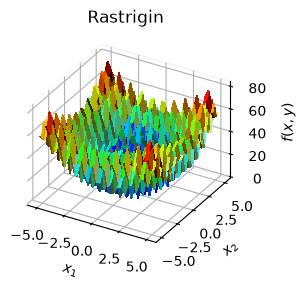

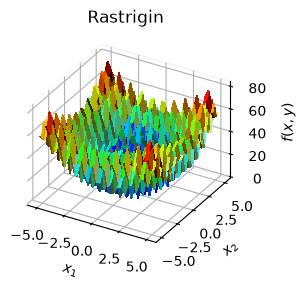

In [2]:
print(len(bf.__all__), bf.__all__)
fun = bf.Rastrigin(2)
fun.plot(samples=40, resolution=100)


`get_function_value` avalia um ponto. Aqui ele monta a malha `X, Y, Z` para desenhar a superfície manualmente. Vamos reaproveitar essa malha como fundo nos gráficos da população.

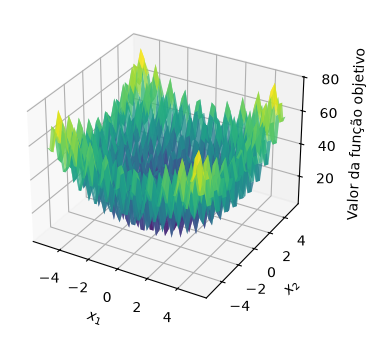

In [3]:
bounds = np.asarray(fun.get_search_range()).T
X, Y = np.meshgrid(*(np.linspace(low, high, 40) for low, high in bounds))
Z = np.array(
    [fun.get_function_value([x, y]) for x, y in zip(X.ravel(), Y.ravel(), strict=True)]
).reshape(X.shape)
fig = plt.figure()
ax = fig.add_subplot(projection="3d")
ax.plot_surface(X, Y, Z, cmap="viridis", alpha=0.8)
ax.set(xlabel="$x_1$", ylabel="$x_2$", zlabel=labels["fitness"])
plt.show()


Domínio, escala, deslocamento e ruído mudam com os métodos `set_*`. Usamos uma instância separada de Ackley para isso. Com ruído, avaliar o mesmo ponto duas vezes dá valores diferentes, então os outros exemplos usam funções sem modificação.

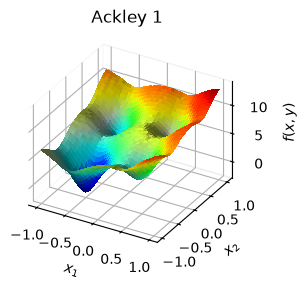

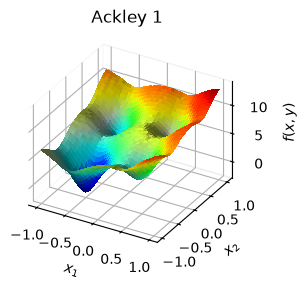

In [4]:
modified_fun = bf.Ackley1(2)
modified_fun.set_search_range([-1.0, -1.0], [1.0, 1.0])
modified_fun.set_offset_function(-2)
modified_fun.set_scale_function(2)
modified_fun.set_noise_level(0.1)
modified_fun.set_offset_domain([0.5, 0.5])
modified_fun.plot(samples=40)


## 2. População e inicialização
`Population` guarda as posições, o valor da função de cada indivíduo e os melhores registros (por indivíduo e global). Internamente as posições ficam em `[-1, 1]`; `get_positions()` converte para o domínio do problema.

A ordem de uso é: inicializar (`initialise_positions`), avaliar (`evaluate_fitness`) e atualizar os registros de população, melhor pessoal e melhor global (`update_positions`). Os operadores esperam esses registros preenchidos. A tabela mostra a mesma coordenada nas duas escalas.

In [5]:
fun = bf.Rastrigin(2)
pop = pp.Population(fun.get_search_range(), num_agents=NUM_AGENTS)
pop.initialise_positions("lhs")
pop.evaluate_fitness(fun.get_function_value)
pop.update_positions("population", "all")
pop.update_positions("particular", "all")
pop.update_positions("global", "greedy")
display(
    pd.DataFrame(
        {
            "x1 [-1, 1]": pop.positions[:, 0],
            "x1 [-5.12, 5.12]": pop.get_positions()[:, 0],
            labels["fitness"]: pop.fitness,
        }
    ).head()
)
print(pop.get_state())


,"x1 [-1, 1]","x1 [-5.12, 5.12]",Valor da função objetivo
0,0.571325,2.925184,31.870401
1,0.811329,4.154002,43.372303
2,0.694293,3.554778,65.148430
3,-0.391283,-2.003370,10.004734
4,0.315194,1.613792,47.350583


x_best = [0.94580783 0.91316946], f_best = 3.754246944714332


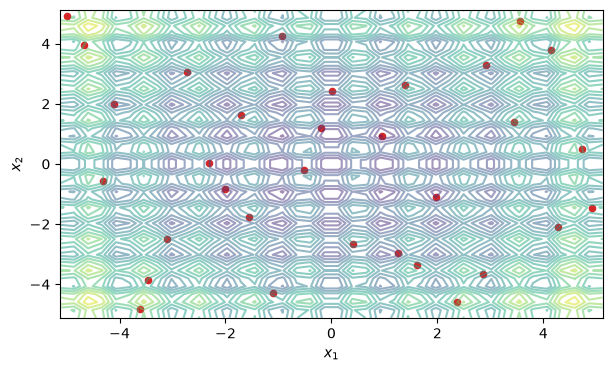

In [6]:
def show_positions(population):
    positions = population.get_positions()
    fig, ax = plt.subplots()
    ax.contour(X, Y, Z, levels=15, cmap="viridis", alpha=0.5)
    ax.scatter(positions[:, 0], positions[:, 1], c="tab:red", s=20)
    ax.set(xlabel="$x_1$", ylabel="$x_2$")
    plt.show()


show_positions(pop)


### 2.1 Métodos de inicialização
`initialise_positions` aceita vários esquemas. Os gráficos abaixo mostram só os pontos de partida (ainda não há busca): 64 indivíduos num domínio quadrado. Os parâmetros das distribuições valem no intervalo unitário, antes da conversão para o domínio.

| Método | Como distribui os pontos |
| --- | --- |
| `random` | Sorteio uniforme. Pode deixar vazios e formar aglomerados. |
| `vertex` | Vértices de quadrados encaixados; não é uma malha cartesiana completa. |
| `lhs` | Hipercubo latino: um ponto em cada uma das 64 faixas de cada eixo. |
| `sobol`, `halton` | Sequências de baixa discrepância, que espalham os pontos com regularidade. `scramble=False` torna a amostra reproduzível. |
| `beta` | Parâmetros menores que 1 puxam os pontos para as bordas; maiores que 1, para o centro. |
| `normal` | Concentra os pontos perto do centro (média 0,5 e desvio 0,25 no intervalo unitário). |
| `lognormal`, `exponential`, `rayleigh` | Distribuições assimétricas. Os valores são recortados em `[0, 1]` antes da conversão, então pontos se acumulam nos limites; isso aparece na lognormal com estes parâmetros. |

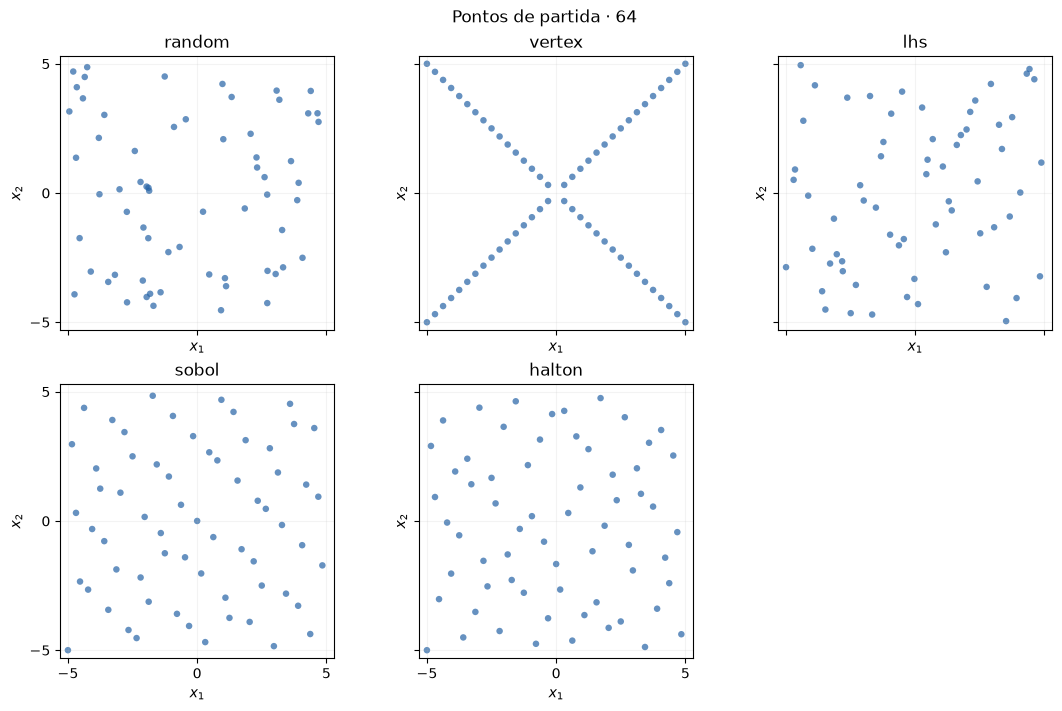

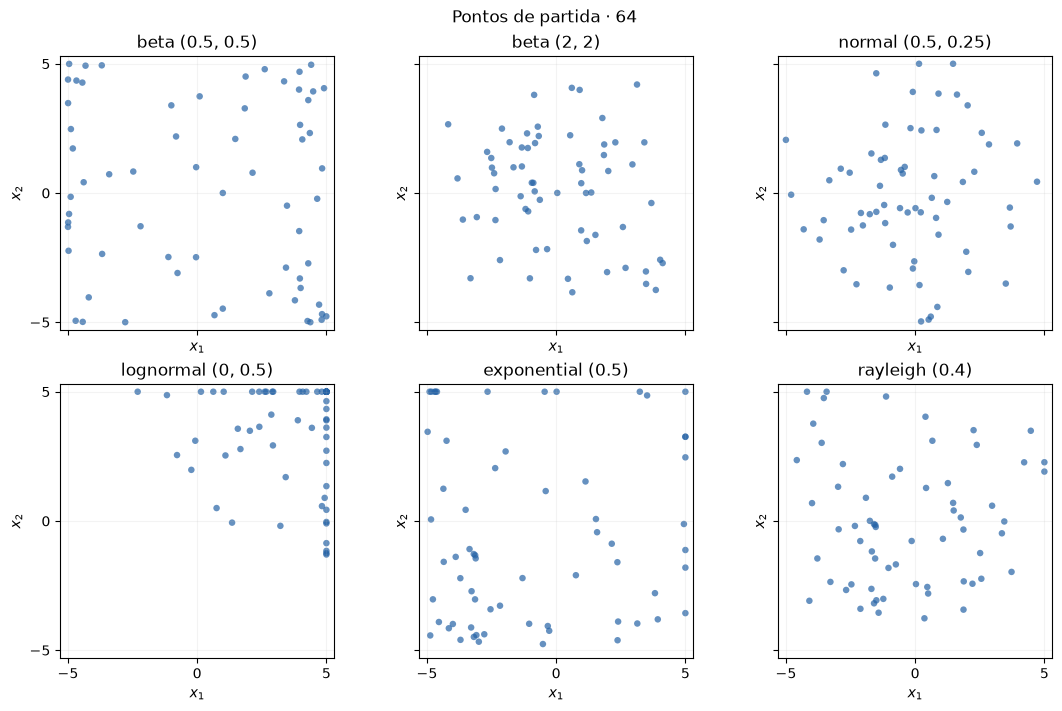

,Inicialização,Pontos distintos,Pontos nos limites (%),Células ocupadas (8 × 8)
0,random,64,0.0,41
1,vertex,64,6.2,22
2,lhs,64,0.0,45
3,sobol,64,1.6,64
4,halton,64,1.6,55
5,"beta (0.5, 0.5)",64,0.0,37
6,"beta (2, 2)",64,0.0,36
7,"normal (0.5, 0.25)",64,4.7,38
8,"lognormal (0, 0.5)",51,70.3,20
9,exponential (0.5),64,25.0,35


In [7]:
INITIAL_AGENTS = 64
initialisation_methods = [
    ("random", "random", {}),
    ("vertex", "vertex", {}),
    ("lhs", "lhs", {}),
    ("sobol", "sobol", {"scramble": False}),
    ("halton", "halton", {"scramble": False}),
    ("beta (0.5, 0.5)", "beta", {"a": 0.5, "b": 0.5}),
    ("beta (2, 2)", "beta", {"a": 2.0, "b": 2.0}),
    ("normal (0.5, 0.25)", "normal", {"mean": 0.5, "std": 0.25}),
    ("lognormal (0, 0.5)", "lognormal", {"mean": 0.0, "sigma": 0.5}),
    ("exponential (0.5)", "exponential", {"scale": 0.5}),
    ("rayleigh (0.4)", "rayleigh", {"scale": 0.4}),
]
initial_samples = {}
for name, scheme, options in initialisation_methods:
    np.random.seed(SEED)
    sample_pop = pp.Population(([-5.0, -5.0], [5.0, 5.0]), num_agents=INITIAL_AGENTS)
    sample_pop.initialise_positions(scheme, **options)
    initial_samples[name] = sample_pop.get_positions().copy()

initialisation_figures = []
for group in (initialisation_methods[:5], initialisation_methods[5:]):
    fig, axes = plt.subplots(2, 3, figsize=(11, 7), sharex=True, sharey=True, layout="constrained")
    for ax, (name, _, _) in zip(axes.flat, group):
        points = initial_samples[name]
        ax.scatter(points[:, 0], points[:, 1], s=22, alpha=0.7, color="#2563a6", edgecolors="none")
        ax.set(title=name, xlim=(-5.3, 5.3), ylim=(-5.3, 5.3), xlabel="$x_1$", ylabel="$x_2$")
        ax.set_aspect("equal")
        ax.set_xticks([-5, 0, 5])
        ax.set_yticks([-5, 0, 5])
        ax.grid(alpha=0.15)
    for ax in list(axes.flat)[len(group) :]:
        ax.set_visible(False)
    fig.suptitle(f"{labels['init_title']} · {INITIAL_AGENTS}")
    initialisation_figures.append(fig)
    plt.show()

initial_summary = []
for name, points in initial_samples.items():
    counts, _, _ = np.histogram2d(points[:, 0], points[:, 1], bins=8, range=[[-5, 5], [-5, 5]])
    initial_summary.append(
        {
            labels["init"]: name,
            labels["unique"]: len(np.unique(points, axis=0)),
            labels["edge"]: 100 * np.any(np.isclose(np.abs(points), 5.0), axis=1).mean(),
            labels["bins"]: np.count_nonzero(counts),
        }
    )
display(pd.DataFrame(initial_summary).round(1))
np.random.seed(SEED)


Pontos sobrepostos parecem um só no gráfico, por isso a tabela conta as coordenadas distintas e os pontos sobre os limites. As células ocupadas valem para esta divisão 8 × 8 e não ranqueiam os métodos. Uma amostra concentrada faz sentido quando se sabe onde está o ótimo; sem essa informação, uma amostra espalhada cobre mais do domínio.

## 3. Operadores e coleções
Um operador é uma tupla `(nome, parâmetros, seletor)`. O operador propõe novas posições e o seletor decide quais ficam: com `greedy`, o indivíduo só muda se o valor da função melhorar. Operadores `initialize_*` reiniciam a população, e a hiper-heurística os trata como inicializadores.

Uma coleção é um arquivo de texto com um operador por linha. A coleção padrão é lida do pacote instalado, então funciona de qualquer diretório.

In [8]:
print(labels["operator"], op.__all__)
print(labels["selector"], op.__selectors__)
collection_text = files("customhys").joinpath("collections/default.txt").read_text(encoding="utf-8")
default_operators = [
    ast.literal_eval(line) for line in collection_text.splitlines() if line.strip()
]
print(len(default_operators))
display(
    pd.DataFrame(
        default_operators, columns=[labels["operator"], labels["parameters"], labels["selector"]]
    ).head(10)
)


Operador ['local_random_walk', 'random_search', 'random_sample', 'random_flight', 'differential_mutation', 'firefly_dynamic', 'swarm_dynamic', 'gravitational_search', 'central_force_dynamic', 'spiral_dynamic', 'genetic_mutation', 'genetic_crossover', 'linear_system', 'initialize_random', 'initialize_sobol', 'initialize_halton', 'initialize_grid', 'initialize_lhs', 'initialize_beta', 'initialize_normal', 'initialize_lognormal', 'initialize_exponential', 'initialize_rayleigh']
Seletor ['all', 'greedy', 'metropolis', 'probabilistic']
217


,Operador,Parâmetros,Seletor
0,initialize_random,{},all
1,initialize_sobol,{'scramble': True},all
2,initialize_sobol,{'scramble': False},all
3,initialize_halton,{'scramble': True},all
4,initialize_halton,{'scramble': False},all
5,initialize_grid,{},all
6,initialize_lhs,{},all
7,initialize_beta,"{'a': 0.5, 'b': 0.5}",all
8,initialize_normal,"{'mean': 0.5, 'std': 0.25}",all
9,initialize_lognormal,"{'mean': 0.0, 'sigma': 0.5}",all


`obtain_operators` lista as famílias de operadores com valores de parâmetros, e `build_operators` grava uma coleção em `collections/` (relativo ao diretório atual). Aqui geramos uma coleção com duas famílias dentro de um diretório temporário, para não sobrescrever nada.

In [9]:
import os
from tempfile import TemporaryDirectory

operator_families = [
    family
    for family in op.obtain_operators(num_vals=2)
    if family[0] in {"random_search", "spiral_dynamic"}
]
original_dir = Path.cwd()
with TemporaryDirectory() as temporary_dir:
    try:
        os.chdir(temporary_dir)
        op.build_operators(heuristics=operator_families, file_name="tutorial")
        generated_text = Path("collections/tutorial.txt").read_text(encoding="utf-8")
    finally:
        os.chdir(original_dir)
generated_operators = [
    ast.literal_eval(line) for line in generated_text.splitlines() if line.strip()
]
print(len(generated_operators))
display(
    pd.DataFrame(
        generated_operators, columns=[labels["operator"], labels["parameters"], labels["selector"]]
    ).head()
)


random_search: parameters=2, combinations:1
random_search: parameters=2, combinations:6
spiral_dynamic: parameters=3, combinations:8
----------------------------------------------------
TOTAL: families=3, operators=57
57


,Operador,Parâmetros,Seletor
0,random_search,"{'scale': 1.0, 'distribution': 'uniform'}",greedy
1,random_search,"{'scale': 0.01, 'distribution': 'uniform'}",all
2,random_search,"{'scale': 0.01, 'distribution': 'uniform'}",greedy
3,random_search,"{'scale': 0.01, 'distribution': 'uniform'}",metropolis
4,random_search,"{'scale': 0.01, 'distribution': 'uniform'}",probabilistic


Um operador em ação: a cada iteração, `random_search` desloca os indivíduos e o seletor `greedy` fica só com as melhorias. As linhas cinza são os valores da população e a linha destacada é o melhor resultado acumulado. Esse laço é, em essência, o que a classe `Metaheuristic` automatiza na próxima seção.

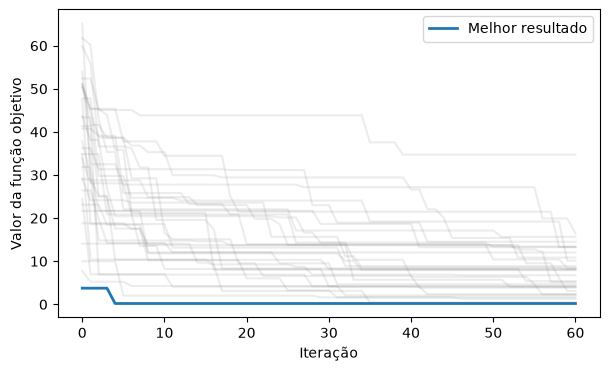

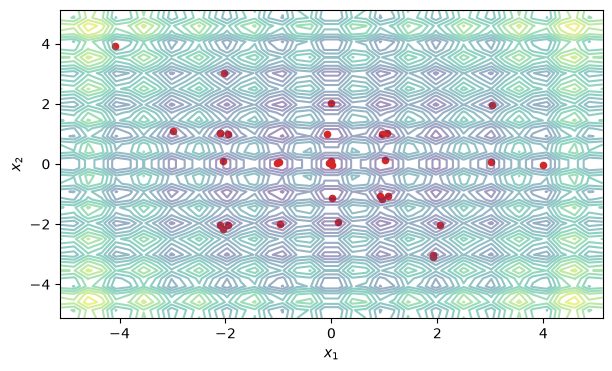

In [10]:
operator_name, operator_params, selector = (
    "random_search",
    {"scale": 0.2, "distribution": "uniform"},
    "greedy",
)
history = [pop.fitness.copy()]
best_history = [pop.global_best_fitness]
for iteration in range(1, NUM_ITERATIONS + 1):
    pop.iteration = iteration
    getattr(op, operator_name)(pop, **operator_params)
    pop.evaluate_fitness(fun.get_function_value)
    pop.update_positions("population", selector)
    pop.update_positions("global", "greedy")
    history.append(pop.fitness.copy())
    best_history.append(pop.global_best_fitness)
history = np.asarray(history)
fig, ax = plt.subplots()
ax.plot(history, color="grey", alpha=0.15)
ax.plot(best_history, lw=2, label=labels["best"])
ax.set(xlabel=labels["iteration"], ylabel=labels["fitness"])
ax.legend()
plt.show()
show_positions(pop)


## 4. Meta-heurísticas
`Metaheuristic` recebe um problema (`get_formatted_problem()`), uma sequência de operadores e o orçamento de busca, e aplica a sequência inteira a cada iteração. O exemplo combina mutação diferencial e cruzamento em Rastrigin com três dimensões, com inicialização `lhs`.

`get_solution()` devolve coordenadas internas; `rescale_back` converte para o domínio do problema e permite conferir o resultado direto na função. `historical` registra o estado depois de cada operador: com dois operadores, cada iteração gera dois registros, além do inicial.

In [11]:
problem_fun = bf.Rastrigin(3)
problem = problem_fun.get_formatted_problem()
differential_sequence = [
    (
        "differential_mutation",
        {"expression": "current-to-best", "num_rands": 2, "factor": 0.8},
        "all",
    ),
    ("differential_crossover", {"crossover_rate": 0.2, "version": "binomial"}, "greedy"),
]
met = mh.Metaheuristic(
    problem,
    differential_sequence,
    num_agents=NUM_AGENTS,
    num_iterations=NUM_ITERATIONS,
    initial_scheme="lhs",
)
met.run()
normalised_best, best_fitness = met.get_solution()
best_position = met.pop.rescale_back(normalised_best)
print("x_best =", best_position, "f_best =", best_fitness)
np.testing.assert_allclose(problem_fun.get_function_value(best_position), best_fitness, atol=1e-10)


x_best = [ 0.03223591 -0.99308494  0.95059585] f_best = 2.5826797442179483


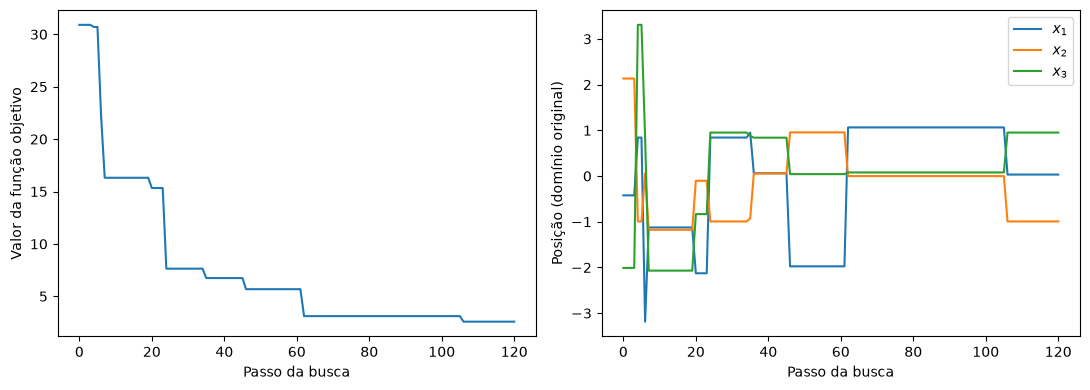

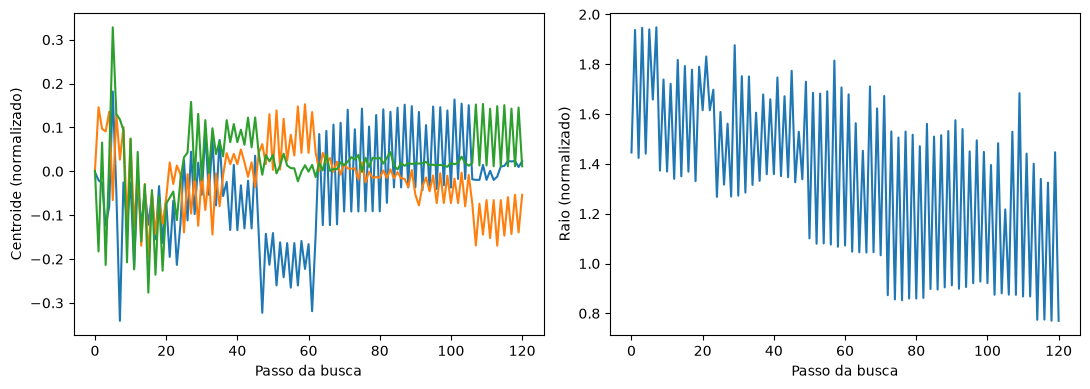

In [12]:
def plot_run(metaheuristic):
    recorded = metaheuristic.historical
    positions = metaheuristic.pop.rescale_back(np.asarray(recorded["position"]))
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    axes[0].plot(recorded["fitness"])
    axes[0].set(xlabel=labels["step"], ylabel=labels["fitness"])
    axes[1].plot(positions)
    axes[1].set(xlabel=labels["step"], ylabel=labels["position"])
    axes[1].legend([f"$x_{i + 1}$" for i in range(metaheuristic.num_dimensions)])
    fig.tight_layout()
    plt.show()


plot_run(met)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(met.historical["centroid"])
axes[0].set(xlabel=labels["step"], ylabel=labels["centroid"])
axes[1].plot(met.historical["radius"])
axes[1].set(xlabel=labels["step"], ylabel=labels["radius"])
fig.tight_layout()
plt.show()


### 4.1 Por onde a população passou
`historical` guarda só o melhor valor e a melhor posição. Para ver a população inteira, a subclasse abaixo sobrescreve `reset_historicals` e `update_historicals`, que o `run()` chama, e guarda todas as posições depois de cada operador e da seleção.

Os mapas mostram a população mantida após a seleção, então movimentos rejeitados não aparecem. As linhas ligam registros consecutivos e não indicam pontos avaliados no caminho. O mapa de ocupação conta visitas repetidas, por isso também reflete quanto tempo os indivíduos ficaram em cada região.

In [13]:
from matplotlib.colors import LogNorm


class TracedMetaheuristic(mh.Metaheuristic):
    def reset_historicals(self):
        super().reset_historicals()
        self.population_history = []
        self.population_fitness = []
        self.trace_iterations = []

    def update_historicals(self):
        super().update_historicals()
        self.population_history.append(self.pop.get_positions().copy())
        self.population_fitness.append(self.pop.fitness.copy())
        self.trace_iterations.append(self.pop.iteration)


def plot_exploration(run, objective, boundaries, optimum):
    path = np.asarray(run.population_history)
    lower, upper = np.asarray(boundaries)
    grid_x, grid_y = np.meshgrid(
        np.linspace(lower[0], upper[0], 100), np.linspace(lower[1], upper[1], 100)
    )
    grid_f = np.array(
        [objective([x, y]) for x, y in zip(grid_x.ravel(), grid_y.ravel(), strict=True)]
    )
    grid_f = grid_f.reshape(grid_x.shape)
    best_path = run.pop.rescale_back(np.asarray(run.historical["position"]))
    fig, axes = plt.subplots(2, 3, figsize=(14, 8), layout="constrained")

    def landscape(ax):
        surface = ax.contourf(
            grid_x, grid_y, np.log10(1 + grid_f), levels=22, cmap="Blues", alpha=0.65
        )
        ax.scatter(*optimum, marker="*", s=130, c="#b42318", zorder=5, label=labels["optimum"])
        ax.set(xlim=(lower[0], upper[0]), ylim=(lower[1], upper[1]), xlabel="$x_1$", ylabel="$x_2$")
        return surface

    for ax, index in zip(axes[0], [0, len(path) // 2, len(path) - 1], strict=True):
        surface = landscape(ax)
        ax.scatter(
            path[index, :, 0],
            path[index, :, 1],
            s=22,
            c="#146b5a",
            edgecolors="white",
            linewidths=0.3,
        )
        ax.scatter(*best_path[index], marker="x", s=70, c="#e07800", zorder=6, label=labels["best"])
        ax.set_title(
            f"{labels['iteration']} {run.trace_iterations[index]} · {labels['record']} {index}"
        )
    axes[0, 0].legend(fontsize=8, loc="upper left")
    fig.colorbar(surface, ax=list(axes[0]), label="log₁₀(1 + f)", shrink=0.8)

    landscape(axes[1, 0])
    for agent in range(min(5, run.num_agents)):
        axes[1, 0].plot(path[:, agent, 0], path[:, agent, 1], lw=0.7, alpha=0.45)
    axes[1, 0].plot(best_path[:, 0], best_path[:, 1], color="#e07800", lw=1.8)
    axes[1, 0].set_title(labels["trajectory"])

    visited = path.reshape(-1, 2)
    density = axes[1, 1].hist2d(
        visited[:, 0],
        visited[:, 1],
        bins=25,
        range=list(zip(lower, upper, strict=True)),
        cmap="YlGnBu",
        norm=LogNorm(),
        cmin=1,
    )
    axes[1, 1].scatter(*optimum, marker="*", c="#b42318", s=100)
    axes[1, 1].set(title=labels["occupancy"], xlabel="$x_1$", ylabel="$x_2$")
    fig.colorbar(density[3], ax=axes[1, 1], label=labels["count"], shrink=0.8)

    axes[1, 2].plot(run.historical["fitness"], color="#146b5a", lw=2)
    axes[1, 2].set(
        title=labels["convergence"], xlabel=labels["record"], ylabel="f(x)", yscale="symlog"
    )
    axes[1, 2].set_yscale('symlog', linthresh=1e-6)
    axes[1, 2].set_ylim(bottom=0)
    axes[1, 2].grid(alpha=0.15)
    plt.show()
    return fig


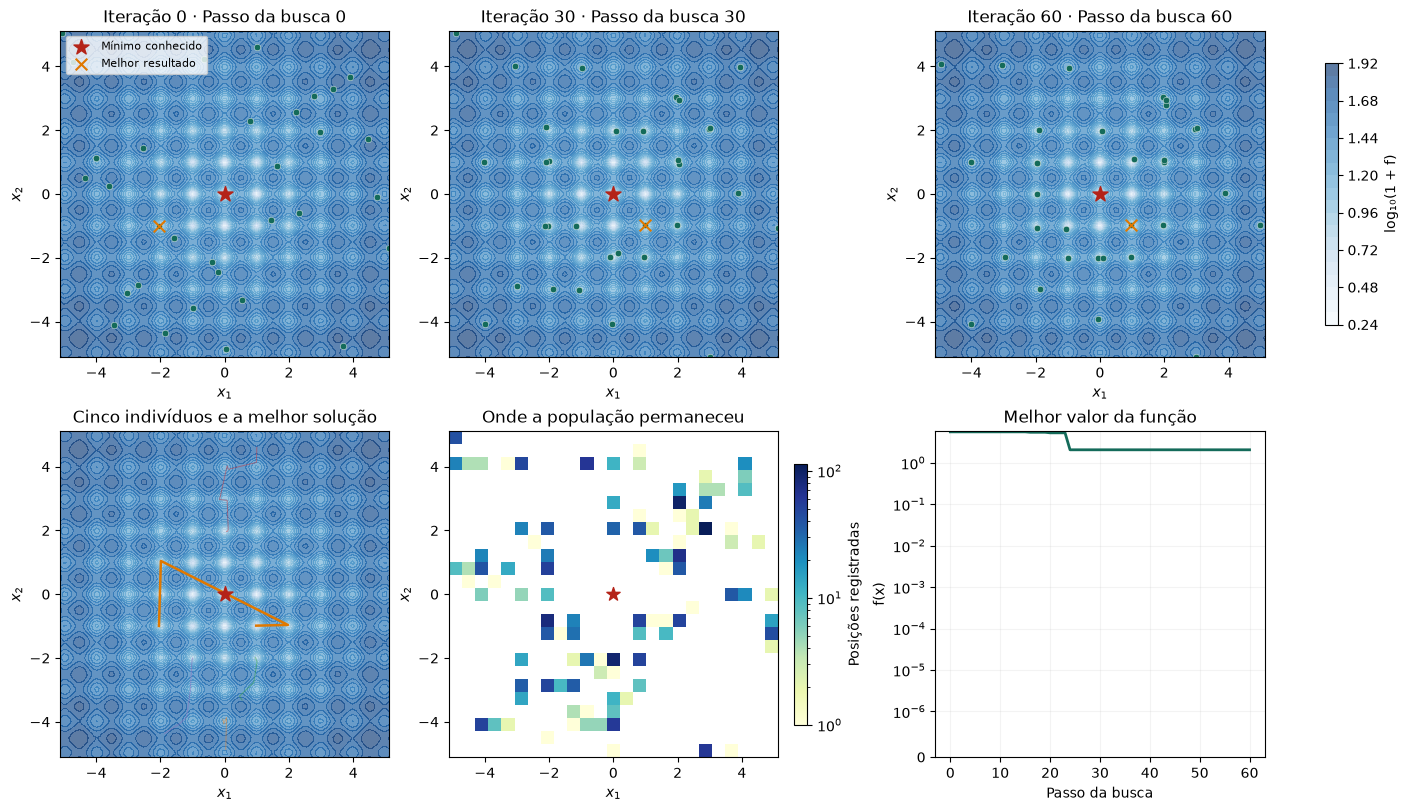

In [14]:
np.random.seed(SEED)
random.seed(SEED)
visual_fun = bf.Rastrigin(2)
visual_problem = visual_fun.get_formatted_problem()
trace_rastrigin = TracedMetaheuristic(
    visual_problem,
    [("random_search", {"scale": 0.08, "distribution": "gaussian"}, "greedy")],
    num_agents=NUM_AGENTS,
    num_iterations=NUM_ITERATIONS,
    initial_scheme="lhs",
)
trace_rastrigin.run()
rastrigin_figure = plot_exploration(
    trace_rastrigin,
    visual_fun.get_function_value,
    visual_problem["boundaries"],
    optimum=(0, 0),
)


### 4.2 Variação entre execuções
Algoritmos estocásticos dão resultados diferentes a cada execução, então uma execução só diz pouco. Aqui combinamos busca aleatória, espiral e busca gravitacional em Griewank com seis dimensões, cada execução com uma semente diferente. A faixa entre P25 e P75 contém a metade central das execuções. Usamos apenas três repetições para o exemplo ser rápido.

,Repetição,Valor da função objetivo
0,1,0.348892
1,2,0.366406
2,3,0.408684


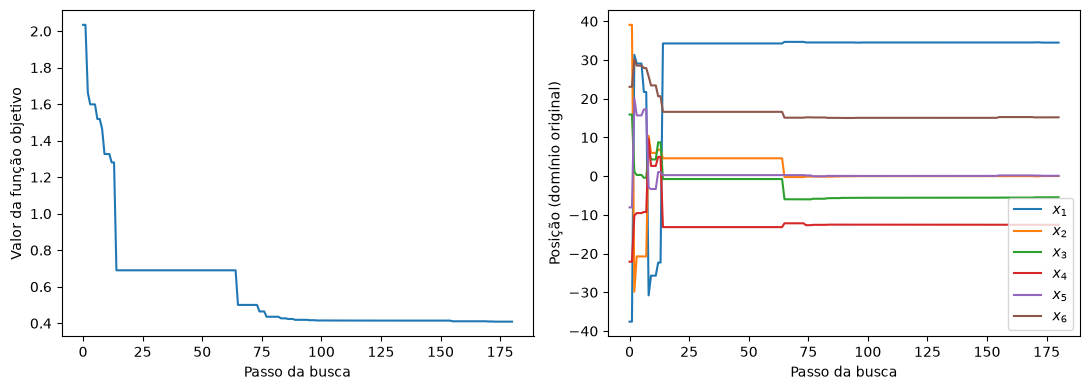

In [15]:
griewank = bf.Griewank(6)
griewank_problem = griewank.get_formatted_problem()
hybrid_sequence = [
    ("random_search", {"scale": 1.0, "distribution": "uniform"}, "greedy"),
    ("spiral_dynamic", {"radius": 0.9, "angle": 33.5, "sigma": 0.1}, "all"),
    ("gravitational_search", {"gravity": 0.5, "alpha": 0.2}, "metropolis"),
]
runs = []
for replica in range(NUM_REPLICAS):
    np.random.seed(SEED + replica)
    random.seed(SEED + replica)
    hybrid_met = mh.Metaheuristic(
        griewank_problem,
        hybrid_sequence,
        num_iterations=NUM_ITERATIONS,
        num_agents=NUM_AGENTS,
    )
    hybrid_met.run()
    runs.append(hybrid_met.historical["fitness"])
fitness_array = np.asarray(runs).T
final_fitness = fitness_array[-1]
display(
    pd.DataFrame(
        {labels["replica"]: np.arange(1, NUM_REPLICAS + 1), labels["fitness"]: final_fitness}
    )
)
plot_run(hybrid_met)


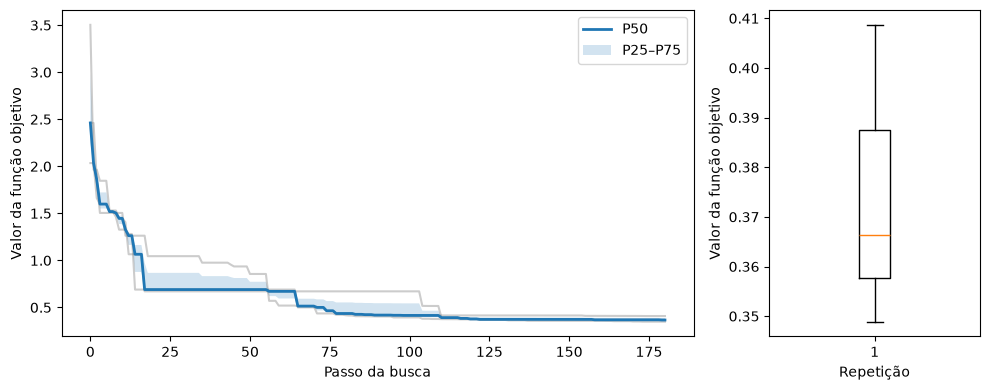

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), gridspec_kw={"width_ratios": [3, 1]})
axes[0].plot(fitness_array, color="grey", alpha=0.4)
axes[0].plot(np.median(fitness_array, axis=1), label="P50", lw=2)
axes[0].fill_between(
    np.arange(len(fitness_array)),
    np.quantile(fitness_array, 0.25, axis=1),
    np.quantile(fitness_array, 0.75, axis=1),
    alpha=0.2,
    label="P25–P75",
)
axes[0].set(xlabel=labels["step"], ylabel=labels["fitness"])
axes[0].legend()
axes[1].boxplot(final_fitness)
axes[1].set(xlabel=labels["replica"], ylabel=labels["fitness"])
fig.tight_layout()
plt.show()


## 5. Hiper-heurística
Até aqui escolhemos o algoritmo à mão. `Hyperheuristic` recebe um espaço de heurísticas (uma lista de operadores) e procura uma sequência que funcione bem para o problema. Aqui o problema é a Sphere em duas dimensões, com mínimo zero em `(0, 0)`.

Cada sequência candidata roda `num_replicas` vezes e é avaliada por `mediana + (P75 − P25)` dos valores finais. A medida combina o resultado típico e sua variação; quanto menor, melhor.

A coleção tem dois inicializadores. O primeiro operador da sequência define como a população começa; um `initialize_*` que apareça depois reinicia a população no meio da busca. Esse comportamento precisa ser preservado ao executar a sequência encontrada.

In [17]:
heuristic_space = [
    ("initialize_random", {}, "all"),
    ("initialize_lhs", {}, "all"),
    ("random_search", {"scale": 0.2, "distribution": "uniform"}, "greedy"),
    (
        "local_random_walk",
        {"probability": 0.75, "scale": 0.2, "distribution": "gaussian"},
        "greedy",
    ),
]
parameters = {
    "cardinality": 3,
    "cardinality_min": 2,
    "num_iterations": 30,
    "num_agents": NUM_AGENTS,
    "as_mh": True,
    "num_replicas": NUM_REPLICAS,
    "num_steps": HH_STEPS,
    "stagnation_percentage": 0.5,
    "max_temperature": 1.0,
    "min_temperature": 1e-6,
    "cooling_rate": 1e-3,
    "temperature_scheme": "fast",
    "acceptance_scheme": "exponential",
    "allow_weight_matrix": False,
    "trial_overflow": False,
    "learnt_dataset": None,
    "repeat_operators": True,
    "verbose": False,
    "learning_portion": 0.37,
    "solver": "static",
    "initial_scheme": "random",
}
np.random.seed(SEED)
random.seed(SEED)
hh_fun = bf.Sphere(2)
hh_problem = hh_fun.get_formatted_problem()
run_label = "tutorial-" + uuid4().hex
hyp = hh.Hyperheuristic(
    heuristic_space=heuristic_space,
    problem=hh_problem,
    parameters=parameters.copy(),
    file_label=run_label,
)
best_sol, best_perf, hist_current, hist_best = hyp.solve(save_steps=True)
best_sequence = hyp.get_operators(best_sol)
print(labels["performance"], best_perf)
display(
    pd.DataFrame(
        best_sequence, columns=[labels["operator"], labels["parameters"], labels["selector"]]
    )
)


Mediana + (P75 − P25) 0.1039233777403248


,Operador,Parâmetros,Seletor
0,initialize_lhs,{},all
1,local_random_walk,"{'probability': 0.75, 'scale': 0.2, 'distribut...",greedy
2,random_search,"{'scale': 0.2, 'distribution': 'uniform'}",greedy


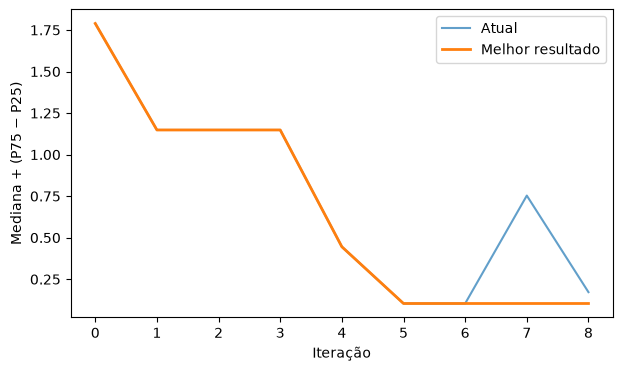

In [18]:
fig, ax = plt.subplots()
ax.plot(hist_current, label=labels["current"], alpha=0.7)
ax.plot(hist_best, label=labels["best"], lw=2)
ax.set(xlabel=labels["iteration"], ylabel=labels["performance"])
ax.legend()
plt.show()


### 5.1 Lendo os resultados
Cada execução grava seus arquivos em `data_files/raw/<rótulo>/`. O solver estático registra a solução inicial e as seguintes que igualam ou melhoram a melhor, ou seja, nem todas as tentativas. `merge_json` junta os registros em um arquivo e `read_json` o carrega.

100%|██████████| 4/4 [00:00<00:00, 1598.29it/s]

Merged file saved: data_files/raw/tutorial-9137f8df7860434abe3c8529955e15a1.json
C:\Users\jneto\Documents\customhys\examples\data_files\raw\tutorial-9137f8df7860434abe3c8529955e15a1


,step,Mediana + (P75 − P25),Operador
0,0,1.789015,"[1, 2]"
1,1,1.148230,"[1, 2]"
2,4,0.445296,"[1, 2, 3]"
3,5,0.103923,"[1, 3, 2]"


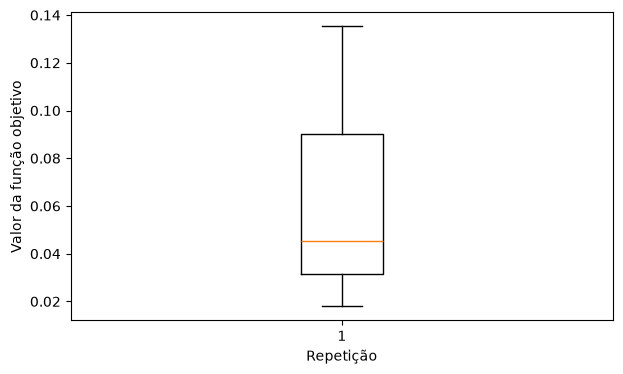

In [19]:
results_dir = Path("data_files") / "raw" / run_label
tl.merge_json(results_dir.as_posix())
full_data = tl.read_json(results_dir.with_suffix(".json").as_posix())
print(results_dir.resolve())
display(
    pd.DataFrame(
        [
            {
                "step": record["step"],
                labels["performance"]: record["performance"],
                labels["operator"]: record["encoded_solution"],
            }
            for record in full_data
        ]
    )
)
saved_fitness = full_data[-1]["details"]["fitness"]
fig, ax = plt.subplots()
ax.boxplot(saved_fitness)
ax.set(xlabel=labels["replica"], ylabel=labels["fitness"])
plt.show()


### 5.2 Executando o algoritmo escolhido
`get_operators` converte os índices devolvidos pela hiper-heurística na sequência de operadores. Se o primeiro for `initialize_*`, ele vira o `initial_scheme` e os demais seguem na mesma ordem. A execução parte de uma população nova; não continua nenhuma das repetições feitas durante a busca.

x_best = [0.07435538 0.27077265] f_best = 0.07884655109155839


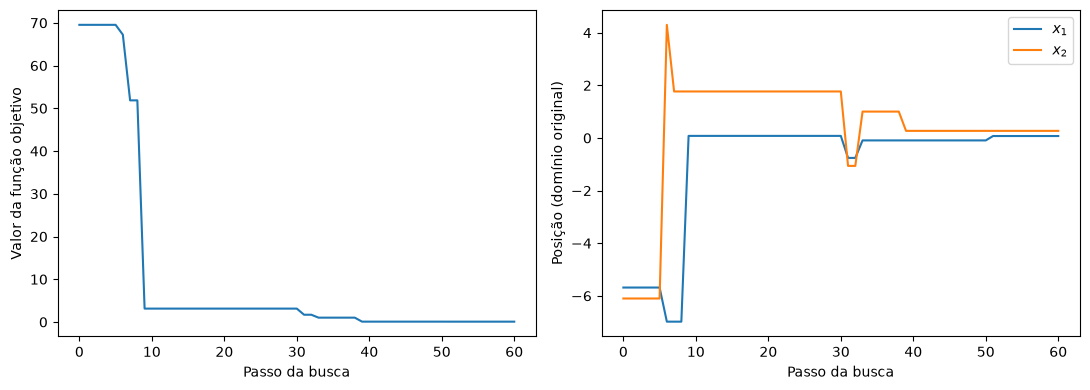

In [20]:
initial_scheme = parameters["initial_scheme"]
discovered_operators = list(best_sequence)
if discovered_operators[0][0].startswith("initialize_"):
    initial_name, initial_params, _ = discovered_operators.pop(0)
    initial_scheme = (initial_name, initial_params)
discovered_met = TracedMetaheuristic(
    hh_problem,
    discovered_operators,
    num_agents=NUM_AGENTS,
    num_iterations=parameters["num_iterations"],
    initial_scheme=initial_scheme,
)
discovered_met.run()
x_normalised, f_best = discovered_met.get_solution()
x_best = discovered_met.pop.rescale_back(x_normalised)
print("x_best =", x_best, "f_best =", f_best)
np.testing.assert_allclose(hh_fun.get_function_value(x_best), f_best, atol=1e-10)
plot_run(discovered_met)


Mapas de uma nova execução do algoritmo escolhido em Sphere. A hiper-heurística busca no espaço das *sequências de operadores*; estes mapas mostram a sequência escolhida buscando no espaço das *coordenadas do problema*. São dois espaços diferentes.

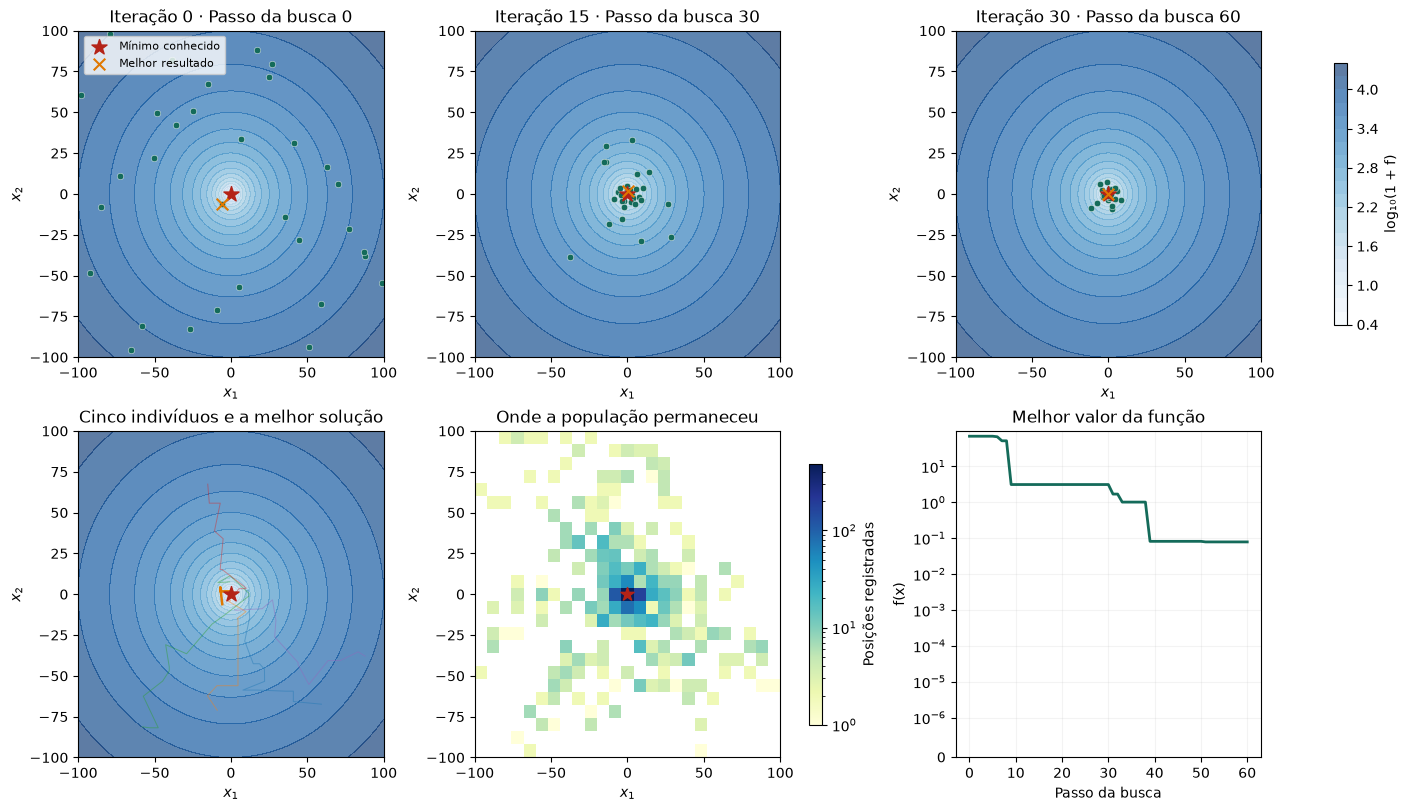

In [21]:
sphere_figure = plot_exploration(
    discovered_met, hh_fun.get_function_value, hh_problem["boundaries"], optimum=(0, 0)
)


## 6. Coleção CEC2005
`CEC2005` reúne problemas de benchmark usados para avaliar algoritmos. A F1 em cinco dimensões é uma Sphere deslocada, então o mínimo não é zero. O uso é o mesmo de antes: `get_formatted_problem()` devolve o dicionário do problema, que vai para a meta-heurística ou para a hiper-heurística.

x_best = [-35.0450719   50.14751139 -52.33428016 -75.19582654 -15.99947893] f_best = -318.1105234367702


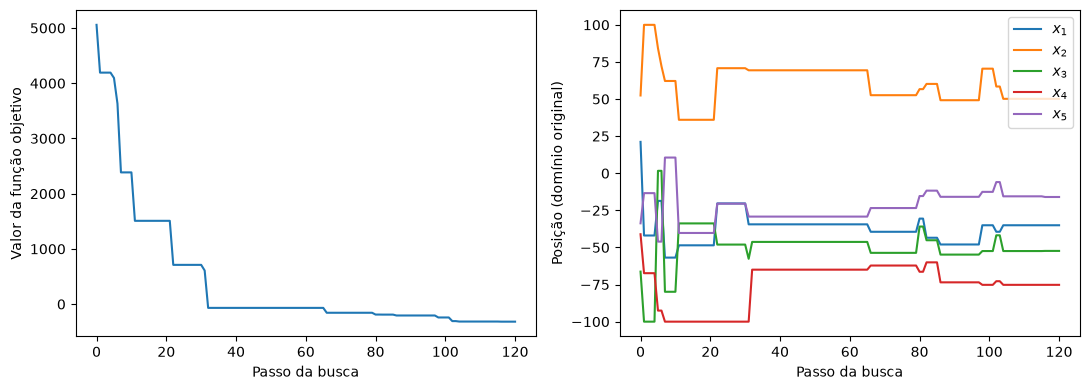

Mediana + (P75 − P25) -224.12380648420185


,Operador,Parâmetros,Seletor
0,initialize_random,{},all
1,random_search,"{'scale': 0.2, 'distribution': 'uniform'}",greedy


In [22]:
cec_fun = bf.CEC2005("F1", 5)
cec_problem = cec_fun.get_formatted_problem()
cec_met = mh.Metaheuristic(
    cec_problem,
    differential_sequence,
    num_iterations=NUM_ITERATIONS,
    num_agents=NUM_AGENTS,
)
cec_met.run()
x_normalised, cec_fitness = cec_met.get_solution()
cec_position = cec_met.pop.rescale_back(x_normalised)
print("x_best =", cec_position, "f_best =", cec_fitness)
np.testing.assert_allclose(cec_fun.get_function_value(cec_position), cec_fitness)
plot_run(cec_met)

cec_hyp = hh.Hyperheuristic(
    heuristic_space=heuristic_space,
    problem=cec_problem,
    parameters=parameters.copy(),
)
cec_sol, cec_perf, _, cec_hist_best = cec_hyp.solve(save_steps=False)
print(labels["performance"], cec_perf)
display(
    pd.DataFrame(
        cec_hyp.get_operators(cec_sol),
        columns=[labels["operator"], labels["parameters"], labels["selector"]],
    )
)


## 7. Definindo o próprio problema: Rosenbrock
Não é preciso uma classe do framework: um dicionário basta. Ele leva a função (que recebe o vetor de coordenadas), os limites `([xmin, ymin], [xmax, ymax])` e `is_constrained=True` para respeitá-los.

A Rosenbrock tem um vale estreito e curvo:

$$\min_{-2 \le x \le 2,\;-1 \le y \le 3} f(x,y)=(1-x)^2+100(y-x^2)^2.$$

Os dois termos se anulam em **(1, 1)**, onde **f = 0**. Chegar ao vale costuma ser fácil; percorrê-lo até o mínimo é o difícil. Como o ótimo é conhecido, dá para conferir o valor da função e a distância até ele.

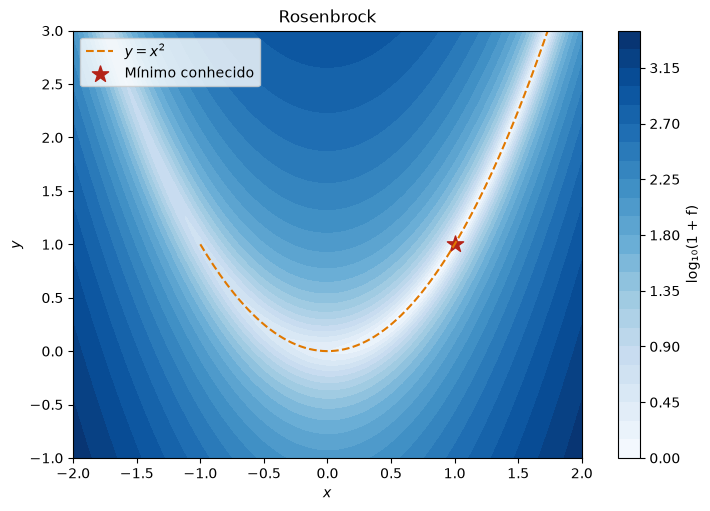

In [23]:
def rosenbrock(point):
    x, y = point
    return float((1 - x) ** 2 + 100 * (y - x**2) ** 2)


rosen_problem = {
    "function": rosenbrock,
    "boundaries": ([-2.0, -1.0], [2.0, 3.0]),
    "is_constrained": True,
}
assert rosenbrock([1.0, 1.0]) == 0.0
assert rosenbrock([0.0, 0.0]) == 1.0

rx, ry = np.meshgrid(np.linspace(-2, 2, 160), np.linspace(-1, 3, 160))
rz = (1 - rx) ** 2 + 100 * (ry - rx**2) ** 2
fig, ax = plt.subplots(figsize=(7, 5), layout="constrained")
surface = ax.contourf(rx, ry, np.log10(1 + rz), levels=25, cmap="Blues")
valley_x = np.linspace(-1, np.sqrt(3), 160)
ax.plot(valley_x, valley_x**2, "--", color="#e07800", lw=1.5, label="$y=x^2$")
ax.scatter(1, 1, s=150, marker="*", color="#b42318", label=labels["optimum"])
ax.set(xlabel="$x$", ylabel="$y$", title="Rosenbrock")
ax.legend()
fig.colorbar(surface, ax=ax, label="log₁₀(1 + f)")
plt.show()


### 7.1 A hiper-heurística monta o algoritmo
O espaço de busca tem movimentos aleatórios em três escalas, um passeio aleatório local e amostragem uniforme (`random_sample`). A inicialização fica fixa em `lhs`, para a busca ser só sobre operadores.

A busca externa testa até 12 alterações de sequência (`num_steps`). Cada candidato roda 80 iterações, com 32 indivíduos e três repetições. Sequências mais longas fazem mais avaliações por iteração. O desempenho mostrado resume as repetições; não é o valor da função em um único ponto.

Mediana + (P75 − P25) 0.00013571226751406954


,Operador,Parâmetros,Seletor
0,random_search,"{'scale': 0.01, 'distribution': 'gaussian'}",greedy
1,random_search,"{'scale': 0.05, 'distribution': 'gaussian'}",greedy
2,local_random_walk,"{'probability': 0.75, 'scale': 0.1, 'distribut...",greedy


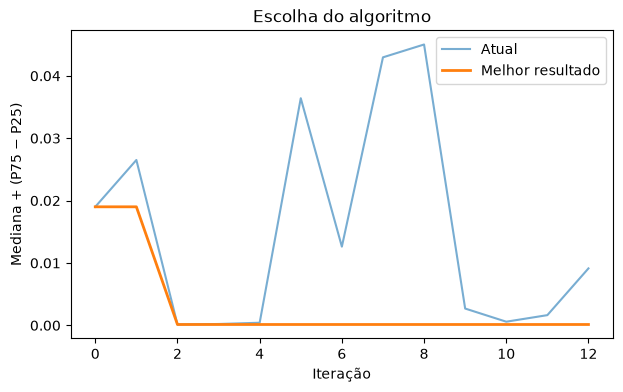

In [24]:
rosen_space = [
    ("random_search", {"scale": scale, "distribution": "gaussian"}, "greedy")
    for scale in (0.01, 0.05, 0.2)
] + [
    (
        "local_random_walk",
        {"probability": 0.75, "scale": 0.1, "distribution": "gaussian"},
        "greedy",
    ),
    ("random_sample", {}, "greedy"),
]
rosen_parameters = {
    **parameters,
    "cardinality_min": 1,
    "cardinality": 3,
    "num_iterations": 80,
    "num_steps": 12,
    "stagnation_percentage": 1.0,
    "initial_scheme": "lhs",
}
np.random.seed(SEED)
random.seed(SEED)
rosen_hyp = hh.Hyperheuristic(
    heuristic_space=rosen_space,
    problem=rosen_problem,
    parameters=rosen_parameters.copy(),
)
rosen_sol, rosen_perf, rosen_current, rosen_best = rosen_hyp.solve(save_steps=False)
rosen_sequence = rosen_hyp.get_operators(rosen_sol)
print(labels["performance"], rosen_perf)
display(
    pd.DataFrame(
        rosen_sequence, columns=[labels["operator"], labels["parameters"], labels["selector"]]
    )
)

fig, ax = plt.subplots()
ax.plot(rosen_current, label=labels["current"], alpha=0.6)
ax.plot(rosen_best, label=labels["best"], lw=2)
ax.set(title=labels["search"], xlabel=labels["iteration"], ylabel=labels["performance"])
ax.legend()
plt.show()


### 7.2 Executando e conferindo a solução
Nova população, nova semente. A tabela traz as coordenadas finais, o valor da função, a distância até `(1, 1)` e o valor inicial. A função é reavaliada nessas coordenadas para conferir o resultado. Com um orçamento pequeno, pode não chegar ao mínimo exato.

,x,y,"f(x, y)","Distância até (1, 1)",Valor inicial da função
0,0.997447,0.995428,3.434298106382746e-05,0.005236,0.6514616619670532


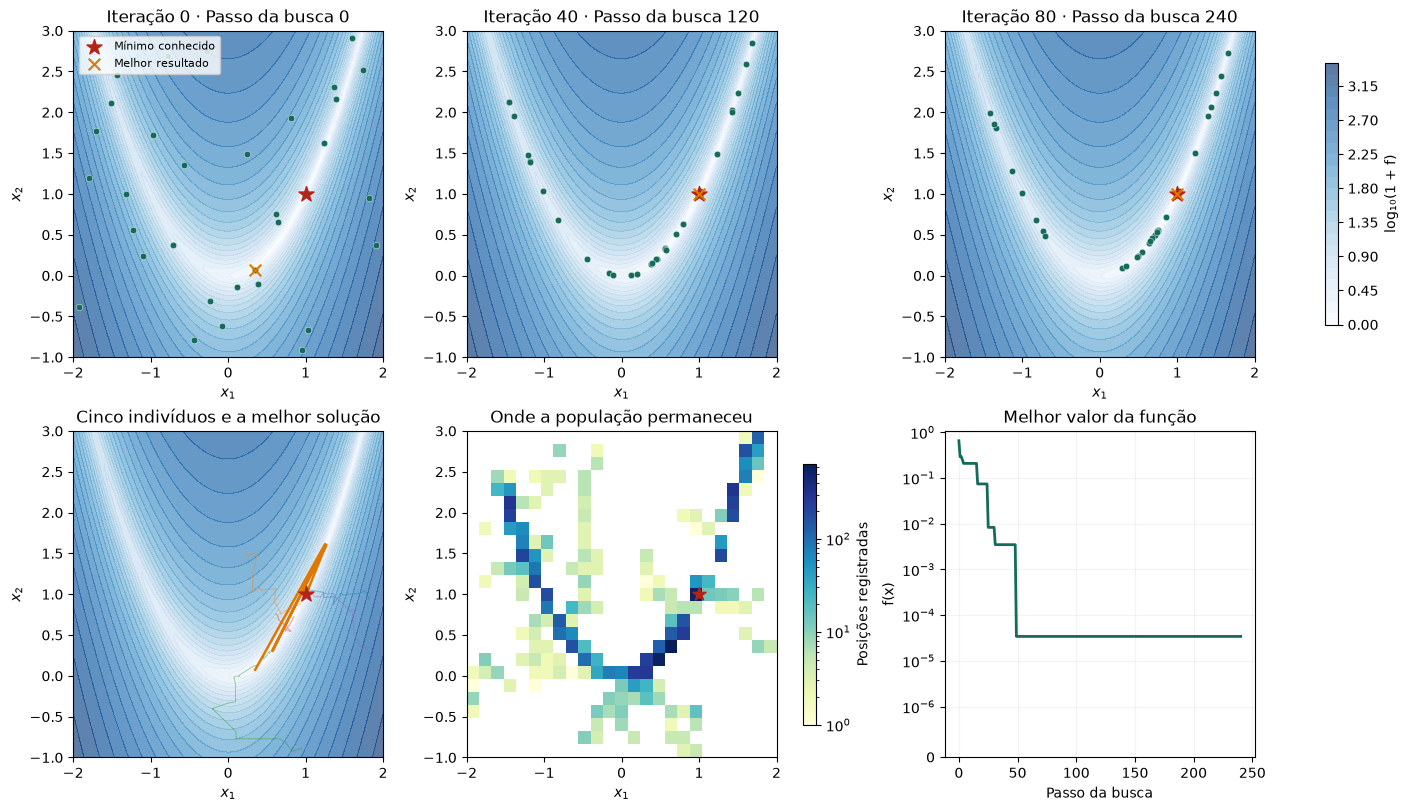

In [25]:
np.random.seed(SEED + 1)
random.seed(SEED + 1)
rosen_run = TracedMetaheuristic(
    rosen_problem,
    rosen_sequence,
    num_agents=NUM_AGENTS,
    num_iterations=rosen_parameters["num_iterations"],
    initial_scheme="lhs",
)
rosen_run.run()
rosen_normalised, rosen_fitness = rosen_run.get_solution()
rosen_position = rosen_run.pop.rescale_back(rosen_normalised)
np.testing.assert_allclose(rosenbrock(rosen_position), rosen_fitness, atol=1e-10)
display(
    pd.DataFrame(
        [
            {
                "x": rosen_position[0],
                "y": rosen_position[1],
                "f(x, y)": rosen_fitness,
                labels["distance"]: np.linalg.norm(rosen_position - np.array([1.0, 1.0])),
                labels["initial"]: rosen_run.historical["fitness"][0],
            }
        ]
    )
)
rosen_figure = plot_exploration(rosen_run, rosenbrock, rosen_problem["boundaries"], optimum=(1, 1))


### 7.3 Animação
Reproduz a população já registrada; não roda uma nova otimização. Dá para pausar e navegar pelos quadros. Os quadros são amostrados para o notebook não ficar pesado (o último sempre entra), e não é preciso instalar codificador de vídeo.

In [ ]:
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

animation_path = np.asarray(rosen_run.population_history)
animation_best = rosen_run.pop.rescale_back(np.asarray(rosen_run.historical["position"]))
frame_indices = np.unique(np.linspace(0, len(animation_path) - 1, 36, dtype=int))
fig, axes = plt.subplots(1, 2, figsize=(9, 3.6), layout="constrained")
axes[0].contourf(rx, ry, np.log10(1 + rz), levels=22, cmap="Blues", alpha=0.65)
axes[0].scatter(1, 1, marker="*", c="#b42318", s=100)
cloud = axes[0].scatter([], [], c="#146b5a", s=18)
marker = axes[0].scatter([], [], marker="x", c="#e07800", s=60)
axes[0].set(xlim=(-2, 2), ylim=(-1, 3), xlabel="$x$", ylabel="$y$")
axes[1].plot(rosen_run.historical["fitness"], color="#146b5a")
cursor = axes[1].axvline(0, color="#e07800")
axes[1].set(xlabel=labels["record"], ylabel="f(x)", title=labels["convergence"], yscale="symlog")


axes[1].set_yscale('symlog', linthresh=1e-6)
axes[1].set_ylim(bottom=0)

def update_frame(index):
    cloud.set_offsets(animation_path[index])
    marker.set_offsets(animation_best[index : index + 1])
    cursor.set_xdata([index, index])
    axes[0].set_title(f"{labels['iteration']} {rosen_run.trace_iterations[index]}")
    return cloud, marker, cursor


animation = FuncAnimation(fig, update_frame, frames=frame_indices, interval=180, repeat=False)
animation_html = animation.to_jshtml(default_mode="once")
plt.close(fig)
display(HTML(animation_html))


: 

## Para experimentar
- Troque só o `initial_scheme`, mantendo função, operadores e número de avaliações, e compare o valor final e a região ocupada.
- Na Rosenbrock, `num_steps` testa mais algoritmos e `num_iterations` dá mais tempo a cada um.
- O [quickTest](quickTest.ipynb) usa o operador de sistemas lineares.